# Practical 7 - CNNs, CVAT, YOLO and Cellpose


##  Hometask: an end-to-end microscopy workflow

Use the datasets supplied in `week7` to create a short, reproducible workflow covering classification, detection, and segmentation. The 3D embedding section may be included as an extension if the required files and compute are available.

## Instructions

1. For blood-cell classification, inspect class balance and image properties, train the baseline CNN, and compare it with one controlled architecture change and one biologically valid augmentation strategy.
2. For colony detection, validate the image/label pairing and YOLO annotation format. Overlay ground-truth boxes on at least three images before training or evaluating a model.
3. Train or evaluate one YOLO nano model and report precision, recall, mAP50, and mAP50-95 on a labelled validation split.
4. Annotate additional images using CVAT and retrain you model.
5. For Cellpose, compare at least two parameter settings involving model, flow threshold, cell-probability threshold, or minimum cell size. Show the masks and explain which setting is biologically more plausible.


## Questions for the report

1. What image, annotation, and split checks were necessary before modelling?
2. Which CNN change or augmentation improved classification, and how do you know it was not caused by a different split?
3. What are the most common YOLO errors: missed objects, false detections, or inaccurate box boundaries?
4. Does the uncertainty ranking select images that look difficult or ambiguous to a human annotator?
5. Which Cellpose parameters changed the masks most, and what trade-off did they create?
6. What information would be needed to compare classification, detection, and segmentation performance fairly across biological experiments?

## Deliverables

- completed notebook;
- representative classification, annotation, detection, uncertainty, and Cellpose figures;
- metrics table for the selected models;
- short answers to the questions.


### Set up

In [10]:

from pathlib import Path
import random
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

RANDOM_STATE = 221026
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


RUN_DATA_DOWNLOAD = True
RUN_EXPENSIVE = True
SHOW_PLOTS = True



print('PyTorch:', torch.__version__)
print('Device:', DEVICE)


PyTorch: 2.8.0
Device: cpu


In [11]:
import os
from pathlib import Path

BASE_DIR = Path('/Users/alina/Documents/Alina/education/kse/year4/term1/ml in bio/KSE_ML_for_bioinformatics/practicals/week7')

# Знаходимо папку, всередині якої лежить 'detection' (працює, навіть якщо є зайва вкладена папка)
week7_dir = next(p.parent for p in BASE_DIR.rglob('detection') if p.is_dir())
os.chdir(week7_dir)

print('Working directory:', Path.cwd())
print('Contents:', sorted(p.name for p in Path.cwd().iterdir()))

!pip install -q ultralytics cellpose kagglehub
# !nvidia-smi --query-gpu=name,memory.total --format=csv

Working directory: /Users/alina/Documents/Alina/education/kse/year4/term1/ml in bio/KSE_ML_for_bioinformatics/practicals/week7
Contents: ['3d', 'ML_in_Bio_p7.ipynb', 'Practical_07_CNN_CVAT_YOLO_Cellpose.ipynb', 'README.md', 'detection', 'hometask', 'segemntation']


## 0. Image and annotation inspection

In [12]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

def locate_week7_root():
    current = Path.cwd().resolve()
    candidates = [current, *current.parents]
    for base in candidates:
        for candidate in (base, base / 'week7'):
            if (candidate / 'detection').is_dir() and any((candidate / name).is_dir() for name in ('segemntation', 'segmentation')):
                return candidate
    return current / 'week7'

# Resolve the root before constructing task-specific paths.
WEEK7_ROOT = locate_week7_root()
PROJECT_ROOT = WEEK7_ROOT.parent
DATA_ROOT = WEEK7_ROOT
CLASSIFICATION_ROOT = DATA_ROOT / 'classification'
DETECTION_ROOT = DATA_ROOT / 'detection' / 'colonies_annotation'
SEGMENTATION_ROOT = next((DATA_ROOT / name for name in ('segemntation', 'segmentation') if (DATA_ROOT / name).is_dir()), DATA_ROOT / 'segmentation')
def image_inventory_row(path, source):
    row = {'source': source, 'file': str(path), 'readable': False}
    try:
        with Image.open(path) as image:
            array = np.asarray(image)
            row.update({
                'readable': True,
                'format': image.format,
                'mode': image.mode,
                'width': image.width,
                'height': image.height,
                'array_shape': tuple(array.shape),
                'dtype': str(array.dtype),
                'channels': 1 if array.ndim == 2 else array.shape[-1],
                'min_intensity': float(np.nanmin(array)),
                'max_intensity': float(np.nanmax(array)),
                'finite': bool(np.isfinite(array).all()),
            })
    except Exception as error:
        row['error'] = repr(error)
    return row

inspection_groups = {
    'detection': sorted((DETECTION_ROOT / 'obj_train_data').glob('*')) if (DETECTION_ROOT / 'obj_train_data').exists() else [],
    'brightfield': sorted((SEGMENTATION_ROOT / 'brightfield').glob('*')) if (SEGMENTATION_ROOT / 'brightfield').exists() else [],
    'CLSM': sorted((SEGMENTATION_ROOT / 'clsm').glob('*')) if (SEGMENTATION_ROOT / 'clsm').exists() else [],
}
inventory_rows = []
for source, paths in inspection_groups.items():
    image_paths = [path for path in paths if path.suffix.lower() in IMAGE_EXTENSIONS]
    for path in image_paths[:5]:
        inventory_rows.append(image_inventory_row(path, source))

if inventory_rows:
    image_inventory = pd.DataFrame(inventory_rows)
    display(image_inventory)
    print('Unreadable files:', int((~image_inventory['readable']).sum()))
else:
    image_inventory = pd.DataFrame()
    print('No local detection or segmentation images were found; continue with the checks after mounting the data.')

,source,file,readable,format,mode,width,height,array_shape,dtype,channels,min_intensity,max_intensity,finite
0,detection,/Users/alina/Documents/Alina/education/kse/yea...,True,JPEG,RGB,850,830,"(830, 850, 3)",uint8,3,0.0,255.0,True
1,brightfield,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,32.0,255.0,True
2,brightfield,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,54.0,255.0,True
3,brightfield,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,47.0,255.0,True
4,brightfield,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,0.0,255.0,True
5,brightfield,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,L,1280,1024,"(1024, 1280)",uint8,1,0.0,255.0,True
6,CLSM,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,RGB,1024,1024,"(1024, 1024, 3)",uint8,3,0.0,255.0,True
7,CLSM,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,RGB,1024,1024,"(1024, 1024, 3)",uint8,3,0.0,255.0,True
8,CLSM,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,RGB,1024,1024,"(1024, 1024, 3)",uint8,3,1.0,255.0,True
9,CLSM,/Users/alina/Documents/Alina/education/kse/yea...,True,TIFF,RGB,1024,1024,"(1024, 1024, 3)",uint8,3,0.0,255.0,True


Unreadable files: 0


## 1. Blood-cell classification

In [13]:
classification_download = None
if RUN_DATA_DOWNLOAD:
    import kagglehub
    classification_download = Path(kagglehub.dataset_download('unclesamulus/blood-cells-image-dataset'))
    print('Path to dataset files:', classification_download)
else:
    print('Kaggle download skipped. Set RUN_DATA_DOWNLOAD=True when network access is available.')

/Users/alina/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


100%|██████████| 268M/268M [00:53<00:00, 5.21MB/s] 

Extracting files...


Path to dataset files: /Users/alina/.cache/kagglehub/datasets/unclesamulus/blood-cells-image-dataset/versions/2


In [14]:
def has_imagefolder_classes(directory):
    if not directory.is_dir():
        return False
    class_dirs = [child for child in directory.iterdir() if child.is_dir()]
    return len(class_dirs) >= 2 and all(
        any(file.suffix.lower() in {'.jpg', '.jpeg', '.png', '.tif', '.tiff'} for file in child.iterdir())
        for child in class_dirs
    )

def find_imagefolder_root(root):
    candidates = [root] + sorted(path for path in root.rglob('*') if path.is_dir())
    valid = [path for path in candidates if has_imagefolder_classes(path)]
    if not valid:
        return None
    return max(valid, key=lambda path: len(list(path.iterdir())))

classification_candidates = [path for path in (classification_download, CLASSIFICATION_ROOT) if path is not None and path.exists()]
classification_root = next((find_imagefolder_root(path) for path in classification_candidates if find_imagefolder_root(path) is not None), None)
if classification_root:
    class_counts = {
        directory.name: sum(1 for file in directory.iterdir() if file.suffix.lower() in {'.jpg', '.jpeg', '.png', '.tif', '.tiff'})
        for directory in sorted(classification_root.iterdir()) if directory.is_dir()
    }
    display(pd.Series(class_counts, name='images').sort_values(ascending=False))
else:
    print('Classification folder not available.')

neutrophil      3329
eosinophil      3117
ig              2895
platelet        2348
erythroblast    1551
monocyte        1420
basophil        1218
lymphocyte      1214
Name: images, dtype: int64

In [15]:
# Image properties of the blood-cell dataset
import hashlib

hw_dataset = datasets.ImageFolder(classification_root)
HW_CLASSES = hw_dataset.classes

rows = []
for path, label in hw_dataset.samples:
    with Image.open(path) as im:
        arr = np.asarray(im)
        rows.append({
            'class': HW_CLASSES[label],
            'mode': im.mode,
            'width': im.width,
            'height': im.height,
            'dtype': str(arr.dtype),
            'min': int(arr.min()),
            'max': int(arr.max()),
            'md5': hashlib.md5(Path(path).read_bytes()).hexdigest(),   # file fingerprint to find exact duplicates
        })
image_properties = pd.DataFrame(rows)

# Summary per class
display(image_properties.groupby('class').agg(
    n=('mode', 'size'),
    modes=('mode', lambda s: ', '.join(sorted(s.unique()))),
    width_min=('width', 'min'), width_max=('width', 'max'),
    height_min=('height', 'min'), height_max=('height', 'max'),
    intensity_min=('min', 'min'), intensity_max=('max', 'max'),
))

# Most common image sizes
print('Most common sizes (width, height):')
print(image_properties.groupby(['width', 'height']).size().sort_values(ascending=False).head(5))

# Exact duplicate files
dup = image_properties[image_properties.duplicated('md5', keep=False)]
print(f'\nExact duplicate files: {len(dup)} files in {dup["md5"].nunique()} groups')

,n,modes,width_min,width_max,height_min,height_max,intensity_min,intensity_max
class,,,,,,,,
basophil,1218,RGB,360,366,363,369,0,255
eosinophil,3117,RGB,360,366,363,369,0,255
erythroblast,1551,RGB,360,362,360,363,0,255
ig,2895,RGB,359,361,360,363,0,255
lymphocyte,1214,RGB,360,366,363,369,0,255
monocyte,1420,RGB,360,366,363,369,0,255
neutrophil,3329,RGB,360,366,363,369,0,255
platelet,2348,RGB,360,360,363,363,0,255


Most common sizes (width, height):
width  height
360    363       16639
366    369         250
360    360         198
       361           2
359    360           1
dtype: int64

Exact duplicate files: 34 files in 17 groups


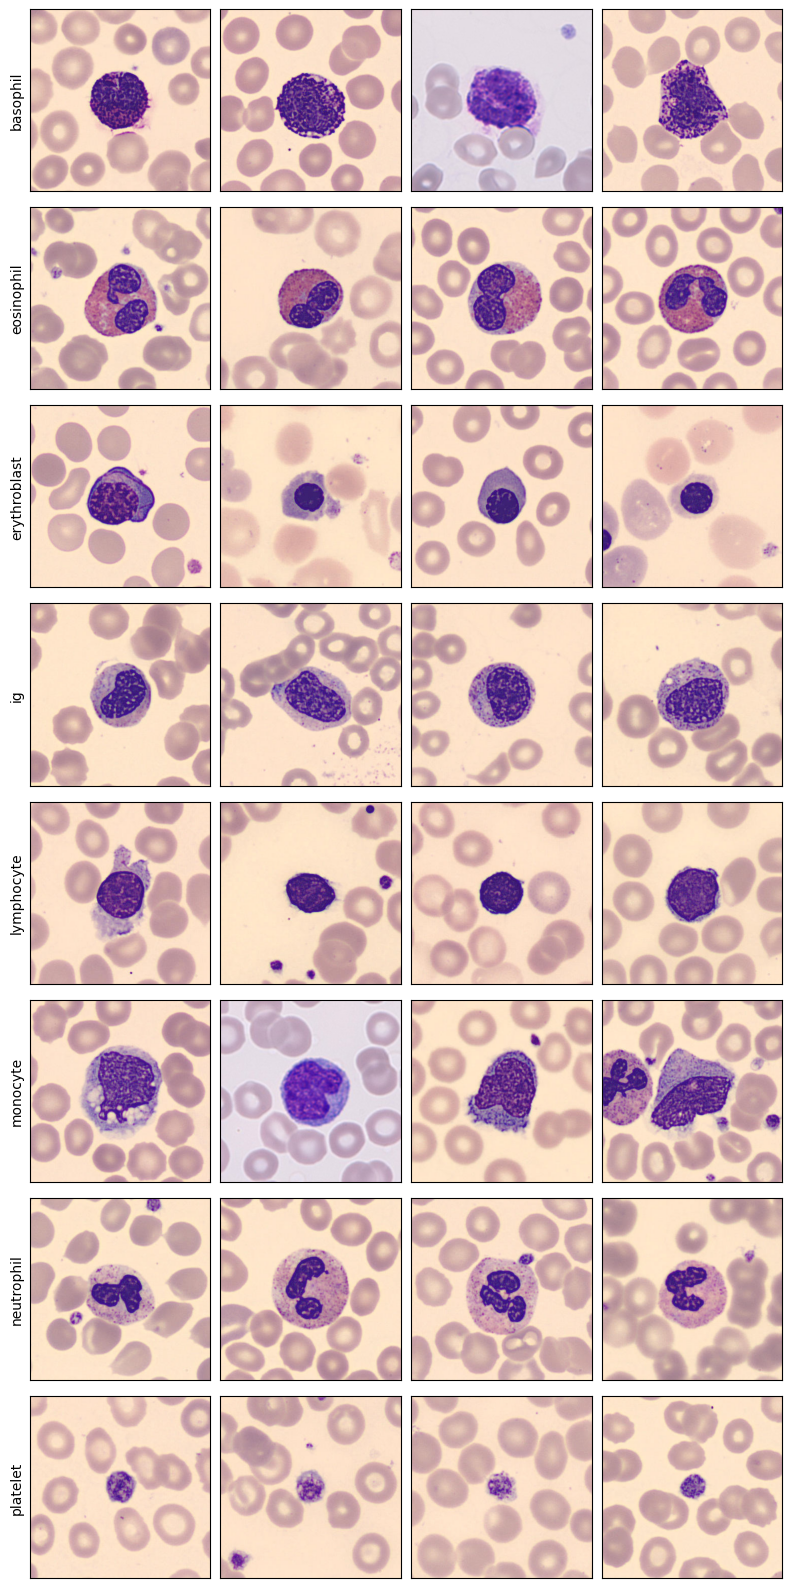

In [16]:
HW_OUT = Path('hometask_outputs')
HW_OUT.mkdir(exist_ok=True)

# Four example images per class
rng = np.random.default_rng(RANDOM_STATE)
targets_all = np.asarray(hw_dataset.targets)
fig, axes = plt.subplots(len(HW_CLASSES), 4, figsize=(8, 2 * len(HW_CLASSES)))
for k, name in enumerate(HW_CLASSES):
    for j, idx in enumerate(rng.choice(np.flatnonzero(targets_all == k), 4, replace=False)):
        with Image.open(hw_dataset.samples[idx][0]) as im:
            axes[k, j].imshow(im)
        axes[k, j].set_xticks([]); axes[k, j].set_yticks([])
    axes[k, 0].set_ylabel(name)
plt.tight_layout(); fig.savefig(HW_OUT / 'cls_examples_per_class.png', dpi=150, bbox_inches='tight'); plt.show()

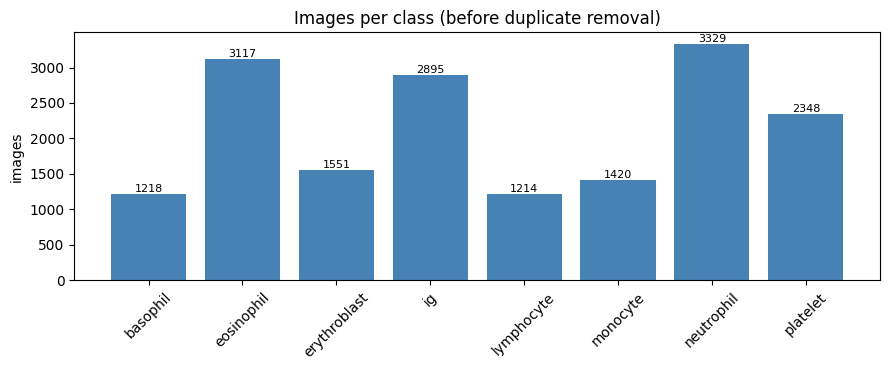

In [17]:
counts = pd.Series(np.asarray(hw_dataset.targets)).map(dict(enumerate(HW_CLASSES))).value_counts().reindex(HW_CLASSES)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(counts.index, counts.values, color='steelblue')
for i, n in enumerate(counts.values):
    ax.text(i, n, str(n), ha='center', va='bottom', fontsize=8)
ax.set(title='Images per class (before duplicate removal)', ylabel='images')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); fig.savefig(HW_OUT / 'cls_class_balance.png', dpi=150, bbox_inches='tight'); plt.show()

There is a slight class imbalance so we will use StratifiedSplit

In [18]:
# Duplicates
image_properties['file'] = [p for p, _ in hw_dataset.samples]

dup = image_properties[image_properties.duplicated('md5', keep=False)]
dup_groups = dup.groupby('md5')['class'].agg(lambda s: sorted(set(s)))
conflicting = dup_groups[dup_groups.apply(len) > 1]

print('Duplicate groups per class:')
print(dup.drop_duplicates('md5')['class'].value_counts())
print(f'\nGroups with CONFLICTING labels: {len(conflicting)}')
conflicting

Duplicate groups per class:
class
eosinophil    7
basophil      6
ig            3
monocyte      1
Name: count, dtype: int64

Groups with CONFLICTING labels: 1


md5
f8ae8b3fb7645a653cdbf48cf968b579    [eosinophil, neutrophil]
Name: class, dtype: object

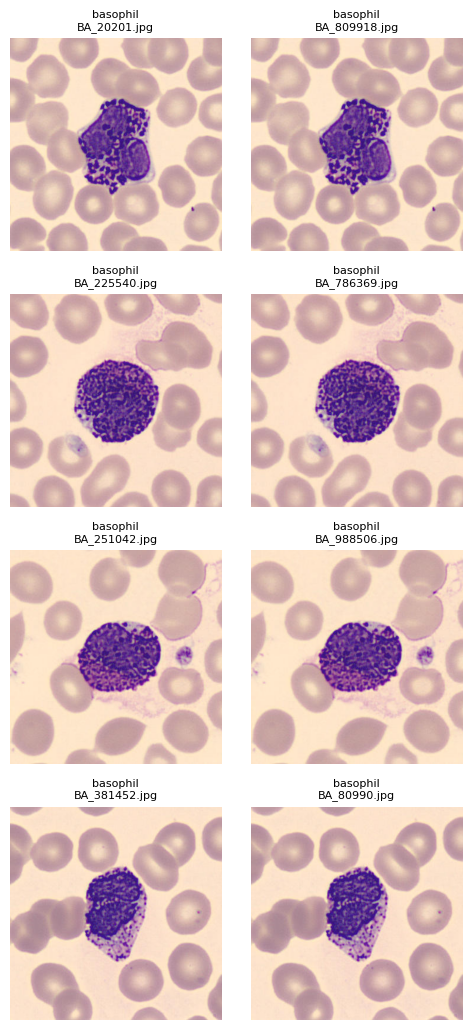

In [19]:
# a few duplicate pairs side by side
show_md5 = dup['md5'].unique()[:4]
fig, axes = plt.subplots(len(show_md5), 2, figsize=(5, 2.6 * len(show_md5)), squeeze=False)
for r, h in enumerate(show_md5):
    pair = dup[dup['md5'] == h].head(2)
    for c, (_, row) in enumerate(pair.iterrows()):
        with Image.open(row['file']) as im:
            axes[r, c].imshow(im)
        axes[r, c].set_title(f"{row['class']}\n{Path(row['file']).name}", fontsize=8)
        axes[r, c].axis('off')
plt.tight_layout()
plt.show()

### Data preperation and split

In [20]:
# Remove conflicting groups and duplicates
HW_OUT = Path('hometask_outputs')
HW_OUT.mkdir(exist_ok=True)

# conflicting groups (same image, different classes) are removed completely
labels_per_md5 = image_properties.groupby('md5')['class'].nunique()
conflict_md5 = set(labels_per_md5[labels_per_md5 > 1].index)

keep_mask = ~image_properties['md5'].isin(conflict_md5)        # drop conflicting files
keep_mask &= ~image_properties.duplicated('md5', keep='first')  # keep only first copy of each duplicate
clean_idx = np.flatnonzero(keep_mask.values)
clean_targets = np.asarray(hw_dataset.targets)[clean_idx]
print(f'Images before cleaning: {len(image_properties)} | after: {len(clean_idx)} '
      f'| removed: {len(image_properties) - len(clean_idx)}')



Images before cleaning: 17092 | after: 17074 | removed: 18


In [21]:
# Stratified split on the cleaned indices
hw_train_idx, tmp_idx = train_test_split(
    clean_idx, test_size=0.2, random_state=RANDOM_STATE, stratify=clean_targets)
tmp_targets = np.asarray(hw_dataset.targets)[tmp_idx]
hw_val_idx, hw_test_idx = train_test_split(
    tmp_idx, test_size=0.5, random_state=RANDOM_STATE, stratify=tmp_targets)

# Sanity checks: no index and no identical file in two subsets
assert not (set(hw_train_idx) & set(hw_val_idx)) and not (set(hw_train_idx) & set(hw_test_idx)) \
       and not (set(hw_val_idx) & set(hw_test_idx))
md5 = image_properties['md5'].values
for a, b, name in [(hw_train_idx, hw_val_idx, 'train-val'),
                   (hw_train_idx, hw_test_idx, 'train-test'),
                   (hw_val_idx, hw_test_idx, 'val-test')]:
    print(f'Identical files shared {name}: {len(set(md5[a]) & set(md5[b]))}')

# Save the split
split_table = image_properties.loc[clean_idx, ['file', 'class']].copy()
split_table['split'] = 'train'
split_table.loc[hw_val_idx, 'split'] = 'val'
split_table.loc[hw_test_idx, 'split'] = 'test'
split_table.to_csv(HW_OUT / 'classification_split.csv', index_label='index')

counts = pd.crosstab(split_table['class'], split_table['split'])[['train', 'val', 'test']]
counts['val_%'] = (counts['val'] / counts.sum(axis=1) * 100).round(1)
counts['test_%'] = (counts['test'] / counts.sum(axis=1) * 100).round(1)
display(counts)

Identical files shared train-val: 0
Identical files shared train-test: 0
Identical files shared val-test: 0


split,train,val,test,val_%,test_%
class,,,,,
basophil,970,121,121,10.0,9.9
eosinophil,2488,311,311,10.0,10.0
erythroblast,1241,155,155,10.0,9.9
ig,2314,289,289,10.0,10.0
lymphocyte,971,121,122,10.0,10.0
monocyte,1135,142,142,10.0,9.9
neutrophil,2662,333,333,10.0,10.0
platelet,1878,235,235,10.0,10.0


### Model, transforms and a training function

In [22]:
import time, copy

HW_IMAGE_SIZE = 128
HW_BATCH_SIZE = 32
HW_EPOCHS = 10
HW_LR = 1e-3
HW_NUM_WORKERS = min(8, os.cpu_count() or 2)

class HWCNN(nn.Module):
    """Baseline from the practical (2 x Conv-ReLU-MaxPool, flatten, linear) with an optional batch norm."""
    def __init__(self, n_classes, image_size=128, batch_norm=False):
        super().__init__()
        layers, in_ch = [], 3
        for out_ch in (16, 32):
            layers.append(nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1))
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_ch))
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            in_ch = out_ch
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * (image_size // 4) ** 2, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))



In [23]:
# Deterministic transform
hw_eval_transform = transforms.Compose([
    transforms.Resize((HW_IMAGE_SIZE, HW_IMAGE_SIZE)),
    transforms.ToTensor(),
])

loader_kwargs = dict(batch_size=HW_BATCH_SIZE, num_workers=HW_NUM_WORKERS, pin_memory=True)
hw_val_loader = DataLoader(Subset(datasets.ImageFolder(classification_root, transform=hw_eval_transform), hw_val_idx),
                           shuffle=False, **loader_kwargs)
hw_test_loader = DataLoader(Subset(datasets.ImageFolder(classification_root, transform=hw_eval_transform), hw_test_idx),
                            shuffle=False, **loader_kwargs)



In [24]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over the loader: trains if an optimizer is given, otherwise only evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * images.size(0)
            y_true.append(labels.cpu()); y_pred.append(logits.argmax(1).cpu())
    y_true, y_pred = torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()
    return total_loss / len(loader.dataset), accuracy_score(y_true, y_pred), y_true, y_pred

def train_experiment(name, train_transform, batch_norm=False, seed=0):
    """Train one configuration; the epoch with the best validation accuracy is kept and evaluated on test."""
    set_seed(seed)
    train_ds = Subset(datasets.ImageFolder(classification_root, transform=train_transform), hw_train_idx)
    train_loader = DataLoader(train_ds, shuffle=True, generator=torch.Generator().manual_seed(seed), **loader_kwargs)

    model = HWCNN(len(HW_CLASSES), HW_IMAGE_SIZE, batch_norm=batch_norm).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=HW_LR)

    history, best_acc, best_state, best_epoch, start = [], -1, None, 0, time.time()
    for epoch in range(1, HW_EPOCHS + 1):
        tr_loss, tr_acc, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = run_epoch(model, hw_val_loader, criterion)
        history.append(dict(experiment=name, seed=seed, epoch=epoch,
                            train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc, val_acc=va_acc))
        print(f'{name} | seed {seed} | epoch {epoch:02d} | train acc {tr_acc:.3f} | val acc {va_acc:.3f} '
              f'| train loss {tr_loss:.3f} | val loss {va_loss:.3f}')
        if va_acc > best_acc:
            best_acc, best_epoch, best_state = va_acc, epoch, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    _, te_acc, y_true, y_pred = run_epoch(model, hw_test_loader, criterion)
    print(f'--> best val acc {best_acc:.4f} at epoch {best_epoch} | test acc {te_acc:.4f} '
          f'| {time.time() - start:.0f} s\n')
    return dict(name=name, seed=seed, history=history, best_val_acc=best_acc, best_epoch=best_epoch,
                test_acc=te_acc, y_true=y_true, y_pred=y_pred,
                n_params=sum(p.numel() for p in model.parameters()))

In [25]:
hw_runs = {}   # all results are collected here: key = (experiment name, seed)
print('Number of parameters, baseline:', sum(p.numel() for p in HWCNN(len(HW_CLASSES)).parameters()))
print('Number of parameters, batch norm:', sum(p.numel() for p in HWCNN(len(HW_CLASSES), batch_norm=True).parameters()))

Number of parameters, baseline: 267240
Number of parameters, batch norm: 267336


#### Train the baseline CNN

In [26]:
hw_runs[('baseline', RANDOM_STATE)] = train_experiment('baseline', hw_eval_transform, batch_norm=False, seed=RANDOM_STATE)

/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


baseline | seed 221026 | epoch 01 | train acc 0.669 | val acc 0.827 | train loss 0.971 | val loss 0.489


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


baseline | seed 221026 | epoch 02 | train acc 0.874 | val acc 0.895 | train loss 0.377 | val loss 0.318


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


baseline | seed 221026 | epoch 03 | train acc 0.911 | val acc 0.878 | train loss 0.264 | val loss 0.347


... (12 outputs left out)

/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


baseline | seed 221026 | epoch 10 | train acc 0.977 | val acc 0.919 | train loss 0.070 | val loss 0.260


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


--> best val acc 0.9186 at epoch 6 | test acc 0.9122 | 1715 s



#### Batch Normalization

In [27]:
# architecture change: batch normalization
HW_SEEDS = [RANDOM_STATE, 1, 2]

for seed in HW_SEEDS:
    if ('baseline', seed) not in hw_runs:
        hw_runs[('baseline', seed)] = train_experiment('baseline', hw_eval_transform, batch_norm=False, seed=seed)
    hw_runs[('batch norm', seed)] = train_experiment('batch norm', hw_eval_transform, batch_norm=True, seed=seed)


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


batch norm | seed 221026 | epoch 01 | train acc 0.790 | val acc 0.729 | train loss 1.057 | val loss 0.942


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


batch norm | seed 221026 | epoch 02 | train acc 0.915 | val acc 0.880 | train loss 0.258 | val loss 0.417


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


batch norm | seed 221026 | epoch 03 | train acc 0.932 | val acc 0.226 | train loss 0.202 | val loss 8.392


... (100 outputs left out)

/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


batch norm | seed 2 | epoch 10 | train acc 0.984 | val acc 0.909 | train loss 0.046 | val loss 0.428


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


--> best val acc 0.9256 at epoch 7 | test acc 0.9286 | 1526 s



In [28]:
#  summary
summary = pd.DataFrame([
    dict(experiment=r['name'], seed=r['seed'], best_epoch=r['best_epoch'],
         val_acc=r['best_val_acc'], test_acc=r['test_acc'])
    for r in hw_runs.values()
])
display(summary)
display(summary.groupby('experiment')[['val_acc', 'test_acc']].agg(['mean', 'std']).round(4))

,experiment,seed,best_epoch,val_acc,test_acc
0,baseline,221026,6,0.918571,0.912178
1,batch norm,221026,8,0.926772,0.930913
2,baseline,1,9,0.915641,0.913934
3,batch norm,1,6,0.928530,0.937939
4,baseline,2,6,0.929115,0.933841
5,batch norm,2,7,0.925600,0.928571


val_acc         test_acc        
              mean     std     mean     std
experiment                                 
baseline    0.9211  0.0071   0.9200  0.0120
batch norm  0.9270  0.0015   0.9325  0.0049

#### Augmmentation

Biologically valid augmentation: a cell on a smear has no preferred orientation.


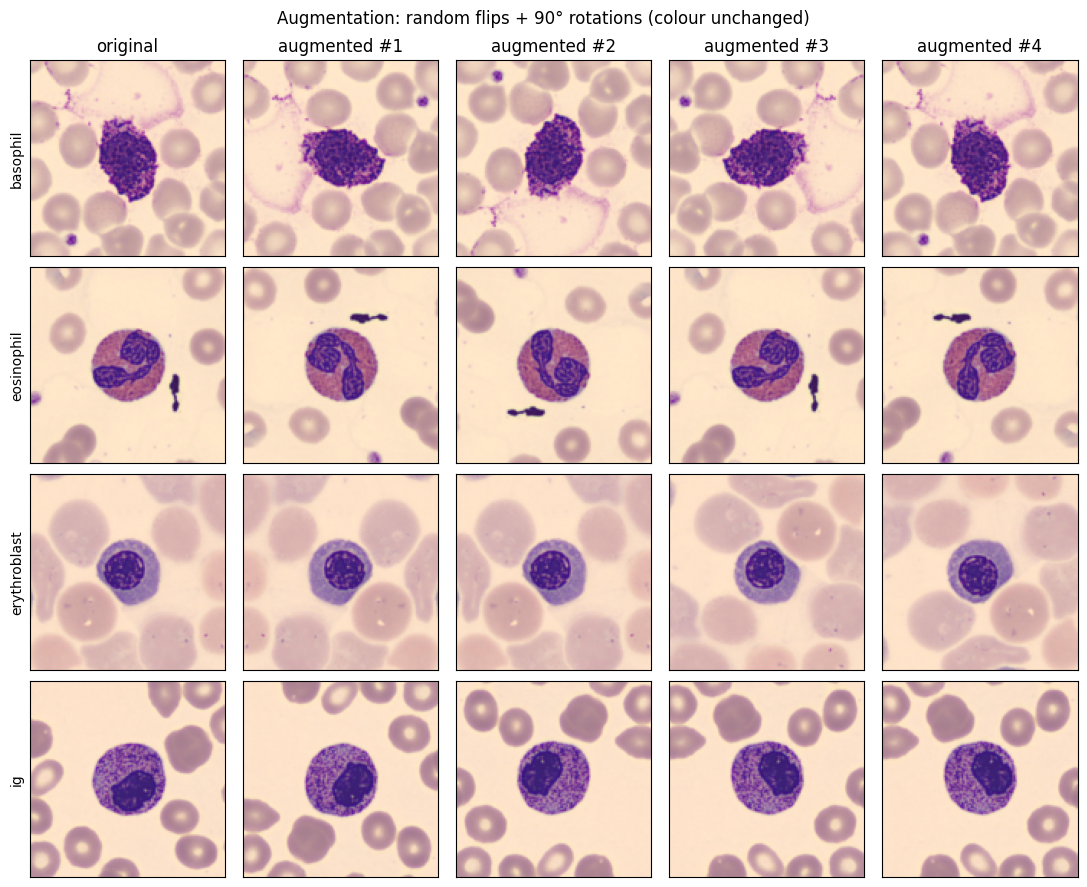

In [29]:
hw_aug_transform = transforms.Compose([
    transforms.Resize((HW_IMAGE_SIZE, HW_IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
    transforms.ToTensor(),
])

# several random augmentations
set_seed(RANDOM_STATE)
targets_all = np.asarray(hw_dataset.targets)
preview_idx = [hw_train_idx[np.flatnonzero(targets_all[hw_train_idx] == k)[0]] for k in range(4)]
fig, axes = plt.subplots(4, 5, figsize=(11, 9))
for r, idx in enumerate(preview_idx):
    path, label = hw_dataset.samples[idx]
    with Image.open(path) as im:
        im = im.convert('RGB')
        axes[r, 0].imshow(hw_eval_transform(im).permute(1, 2, 0))
        for c in range(1, 5):
            axes[r, c].imshow(hw_aug_transform(im).permute(1, 2, 0))
    axes[r, 0].set_ylabel(HW_CLASSES[label])
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title('original')
for c in range(1, 5):
    axes[0, c].set_title(f'augmented #{c}')
fig.suptitle('Augmentation: random flips + 90° rotations (colour unchanged)')
plt.tight_layout()
fig.savefig(HW_OUT / 'cls_augmentation_examples.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
#  baseline architecture + augmentation
for seed in HW_SEEDS:
    hw_runs[('augmentation', seed)] = train_experiment('augmentation', hw_aug_transform, batch_norm=False, seed=seed)

summary = pd.DataFrame([
    dict(experiment=r['name'], seed=r['seed'], best_epoch=r['best_epoch'],
         val_acc=r['best_val_acc'], test_acc=r['test_acc'])
    for r in hw_runs.values()
])
display(summary.sort_values(['experiment', 'seed']))
display(summary.groupby('experiment')[['val_acc', 'test_acc']].agg(['mean', 'std']).round(4))

/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


augmentation | seed 221026 | epoch 01 | train acc 0.661 | val acc 0.821 | train loss 0.995 | val loss 0.531


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


augmentation | seed 221026 | epoch 02 | train acc 0.852 | val acc 0.889 | train loss 0.436 | val loss 0.343


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


augmentation | seed 221026 | epoch 03 | train acc 0.879 | val acc 0.883 | train loss 0.349 | val loss 0.345


... (23 outputs left out)

augmentation | seed 1 | epoch 04 | train acc 0.868 | val acc 0.876 | train loss 0.380 | val loss 0.374


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


augmentation | seed 1 | epoch 05 | train acc 0.886 | val acc 0.900 | train loss 0.320 | val loss 0.297


/Users/alina/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


In [ ]:
# metrics table and learning curves
from sklearn.metrics import f1_score

runs = pd.DataFrame([
    dict(experiment=r['name'], seed=r['seed'], parameters=r['n_params'], best_epoch=r['best_epoch'],
         val_acc=r['best_val_acc'], test_acc=r['test_acc'],
         test_macro_f1=f1_score(r['y_true'], r['y_pred'], average='macro'))
    for r in hw_runs.values()
])
order = ['baseline', 'batch norm', 'augmentation']
cls_metrics = runs.groupby('experiment').agg(
    parameters=('parameters', 'first'),
    val_acc_mean=('val_acc', 'mean'), val_acc_std=('val_acc', 'std'),
    test_acc_mean=('test_acc', 'mean'), test_acc_std=('test_acc', 'std'),
    test_macro_f1_mean=('test_macro_f1', 'mean'), test_macro_f1_std=('test_macro_f1', 'std'),
).loc[order]
display(cls_metrics.round(4))
runs.to_csv(HW_OUT / 'classification_runs_per_seed.csv', index=False)
cls_metrics.to_csv(HW_OUT / 'classification_metrics.csv')


In [ ]:

# Learning curves: mean over seeds, shaded band = min..max across seeds
history = pd.DataFrame([row for r in hw_runs.values() for row in r['history']])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in order:
    h = history[history.experiment == name].groupby('epoch')
    for ax, metric in zip(axes, ['loss', 'acc']):
        va, tr = h[f'val_{metric}'], h[f'train_{metric}']
        line, = ax.plot(va.mean().index, va.mean(), marker='o', ms=3, label=f'{name} – val')
        ax.fill_between(va.mean().index, va.min(), va.max(), color=line.get_color(), alpha=0.15)
        ax.plot(tr.mean().index, tr.mean(), '--', color=line.get_color(), alpha=0.7, label=f'{name} – train')
axes[0].set(title='Loss (mean over 3 seeds)', xlabel='epoch', ylabel='cross-entropy')
axes[0].set_ylim(0, 1.5)   # batch-norm spikes go much higher; clipped for readability
axes[1].set(title='Accuracy (mean over 3 seeds)', xlabel='epoch', ylabel='accuracy')
axes[1].legend(fontsize=8, loc='lower right')
plt.tight_layout()
fig.savefig(HW_OUT / 'cls_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# per-class report and confusion matrices (model with best val acc)
best_key = max(hw_runs, key=lambda k: hw_runs[k]['best_val_acc'])
best = hw_runs[best_key]
base = hw_runs[('baseline', best_key[1])]
print(f'Selected on validation: {best_key} | val acc {best["best_val_acc"]:.4f} | test acc {best["test_acc"]:.4f}\n')
print(classification_report(best['y_true'], best['y_pred'], target_names=HW_CLASSES, digits=3))


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (title, r) in zip(axes, [(f'baseline (seed {best_key[1]})', base),
                                 (f'{best_key[0]} (seed {best_key[1]})', best)]):
    ConfusionMatrixDisplay.from_predictions(
        r['y_true'], r['y_pred'], display_labels=HW_CLASSES, normalize='true',
        values_format='.2f', cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'{title} – test, rows normalised (recall)')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
fig.savefig(HW_OUT / 'cls_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Misclassified test images of the selected model
rng = np.random.default_rng(RANDOM_STATE)

wrong = np.flatnonzero(best['y_true'] != best['y_pred'])
print(f'Misclassified: {len(wrong)} / {len(best["y_true"])}')
fig, axes = plt.subplots(2, 6, figsize=(14, 5.5))
for ax, i in zip(axes.ravel(), rng.choice(wrong, min(12, len(wrong)), replace=False)):
    with Image.open(hw_dataset.samples[hw_test_idx[i]][0]) as im:
        ax.imshow(im)
    ax.set_title(f'true: {HW_CLASSES[best["y_true"][i]]}\npred: {HW_CLASSES[best["y_pred"][i]]}', fontsize=9)
    ax.axis('off')
fig.suptitle(f'Misclassified test images – {best_key[0]} (seed {best_key[1]})')
plt.tight_layout(); fig.savefig(HW_OUT / 'cls_misclassified.png', dpi=150, bbox_inches='tight'); plt.show()


In [ ]:

# save to the google drive
!mkdir -p /content/drive/MyDrive/week7_results && cp -r hometask_outputs/* /content/drive/MyDrive/week7_results/

## 2. Colony detection

### Annotation checks

In [ ]:
import shutil
from matplotlib.patches import Rectangle

DET_IMG_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}
DET_OUT = HW_OUT / 'detection'
DET_OUT.mkdir(parents=True, exist_ok=True)

DET_DATA_DIR = DETECTION_ROOT / 'obj_train_data'
names_file = DETECTION_ROOT / 'obj.names'
DET_CLASSES = [l.strip() for l in names_file.read_text().splitlines() if l.strip()] if names_file.exists() else ['colony']

det_images = {p.stem: p for p in sorted(DET_DATA_DIR.iterdir()) if p.suffix.lower() in DET_IMG_EXT}
det_labels = {p.stem: p for p in sorted(DET_DATA_DIR.glob('*.txt'))}

print('Classes:', DET_CLASSES)
print('Images:', len(det_images), '| label files:', len(det_labels))
print('Images without a label file:', sorted(set(det_images) - set(det_labels)))
print('Label files without an image:', sorted(set(det_labels) - set(det_images)))

In [ ]:
def parse_yolo_label(path):
    boxes, problems = [], []
    for n, line in enumerate(path.read_text().splitlines(), 1):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 5:
            problems.append((path.name, n, 'expected 5 fields'))
            continue
        try:
            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            problems.append((path.name, n, 'non-numeric value'))
            continue
        if cls not in range(len(DET_CLASSES)):
            problems.append((path.name, n, 'class id out of range'))
        if w <= 0 or h <= 0 or not all(0 <= v <= 1 for v in (x, y, w, h)):
            problems.append((path.name, n, 'values outside (0, 1]'))
        elif x - w / 2 < -1e-6 or y - h / 2 < -1e-6 or x + w / 2 > 1 + 1e-6 or y + h / 2 > 1 + 1e-6:
            problems.append((path.name, n, 'box extends beyond image'))
        boxes.append((cls, x, y, w, h))
    return boxes, problems

det_rows, det_problems, det_boxes = [], [], {}
for stem in sorted(set(det_images) & set(det_labels)):
    boxes, problems = parse_yolo_label(det_labels[stem])
    det_boxes[stem] = boxes
    det_problems += problems
    with Image.open(det_images[stem]) as im:
        width, height = im.size
    det_rows.append({'image': det_images[stem].name, 'stem': stem, 'width': width, 'height': height, 'n_boxes': len(boxes)})
det_table = pd.DataFrame(det_rows)

print('Format problems:', len(det_problems))
display(pd.DataFrame(det_problems, columns=['file', 'line', 'problem']).head(20))
print('Images without any box:', int((det_table['n_boxes'] == 0).sum()))
display(det_table[['width', 'height', 'n_boxes']].describe().round(1))
print(det_table.groupby(['width', 'height']).size().sort_values(ascending=False).head(5))

all_boxes = np.array([b[1:] for boxes in det_boxes.values() for b in boxes])
print('Total boxes:', len(all_boxes))
print('Box width / height (normalised), median:', np.median(all_boxes[:, 2]).round(3), '/', np.median(all_boxes[:, 3]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(det_table['n_boxes'], bins=20, color='steelblue')
axes[0].set(title='Boxes per image', xlabel='boxes', ylabel='images')
axes[1].scatter(all_boxes[:, 2], all_boxes[:, 3], s=6, alpha=0.4, color='steelblue')
axes[1].set(title='Box size (normalised)', xlabel='width', ylabel='height')
plt.tight_layout()
fig.savefig(DET_OUT / 'det_annotation_stats.png', dpi=150, bbox_inches='tight')
plt.show()

### Ground-truth overlay

In [ ]:
def yolo_to_xyxy(boxes, width, height):
    return np.array([[(x - w / 2) * width, (y - h / 2) * height, (x + w / 2) * width, (y + h / 2) * height]
                     for _, x, y, w, h in boxes]).reshape(-1, 4)

def draw_xyxy(ax, xyxy, color, scores=None, lw=1.2):
    for i, (x1, y1, x2, y2) in enumerate(xyxy):
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=lw))
        if scores is not None:
            ax.text(x1, y1, f'{scores[i]:.2f}', color=color, fontsize=6, va='bottom')

rng = np.random.default_rng(RANDOM_STATE)
with_boxes = [s for s in det_boxes if det_boxes[s]]
overlay_stems = rng.choice(with_boxes, 4, replace=False)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, stem in zip(axes.ravel(), overlay_stems):
    with Image.open(det_images[stem]) as im:
        im = im.convert('RGB')
        ax.imshow(im)
        draw_xyxy(ax, yolo_to_xyxy(det_boxes[stem], im.width, im.height), 'lime')
    ax.set_title(f'{det_images[stem].name} | {len(det_boxes[stem])} boxes', fontsize=9)
    ax.axis('off')
plt.tight_layout()
fig.savefig(DET_OUT / 'det_gt_overlay.png', dpi=150, bbox_inches='tight')
plt.show()

### Train / validation split

In [ ]:
DET_YOLO_DIR = DET_OUT / 'yolo_dataset'
DET_YOLO_PLUS_DIR = DET_OUT / 'yolo_dataset_plus'

det_items = [(det_images[s], det_labels[s]) for s in det_boxes if det_boxes[s]]
det_train_items, det_val_items = train_test_split(det_items, test_size=0.2, random_state=RANDOM_STATE)

assert not ({i.stem for i, _ in det_train_items} & {i.stem for i, _ in det_val_items})
print('train:', len(det_train_items), '| val:', len(det_val_items))

def build_yolo_dataset(root, train_items, val_items):
    if root.exists():
        shutil.rmtree(root)
    for split, items in (('train', train_items), ('val', val_items)):
        (root / 'images' / split).mkdir(parents=True)
        (root / 'labels' / split).mkdir(parents=True)
        for img, lab in items:
            shutil.copy2(img, root / 'images' / split / img.name)
            shutil.copy2(lab, root / 'labels' / split / (img.stem + '.txt'))
    yaml_path = root / 'data.yaml'
    yaml_path.write_text(
        f'path: {root.resolve()}\ntrain: images/train\nval: images/val\nnames:\n'
        + ''.join(f'  {i}: {n}\n' for i, n in enumerate(DET_CLASSES))
    )
    return yaml_path

det_yaml = build_yolo_dataset(DET_YOLO_DIR, det_train_items, det_val_items)

### YOLO nano: baseline

In [ ]:
from ultralytics import YOLO

YOLO_DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
YOLO_EPOCHS = 50
YOLO_IMGSZ = 640
YOLO_BATCH = 8
YOLO_RUNS = (DET_OUT / 'runs').resolve()

def train_yolo(name, data_yaml, epochs=YOLO_EPOCHS):
    model = YOLO('yolov8n.pt')
    model.train(data=str(data_yaml), epochs=epochs, imgsz=YOLO_IMGSZ, batch=YOLO_BATCH, seed=RANDOM_STATE,
                deterministic=True, device=YOLO_DEVICE, project=str(YOLO_RUNS), name=name, exist_ok=True,
                workers=HW_NUM_WORKERS, plots=True, verbose=False)
    return YOLO(str(YOLO_RUNS / name / 'weights' / 'best.pt'))

def eval_yolo(model, data_yaml):
    m = model.val(data=str(data_yaml), split='val', imgsz=YOLO_IMGSZ, device=YOLO_DEVICE, plots=True, verbose=False)
    return {'precision': m.box.mp, 'recall': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map}

yolo_base = train_yolo('baseline', det_yaml)
det_metrics = {'baseline': eval_yolo(yolo_base, det_yaml)}
display(pd.DataFrame(det_metrics).T.round(4))

In [ ]:
history_base = pd.read_csv(YOLO_RUNS / 'baseline' / 'results.csv')
history_base.columns = history_base.columns.str.strip()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col in ('train/box_loss', 'val/box_loss'):
    axes[0].plot(history_base['epoch'], history_base[col], label=col)
axes[0].set(title='Box loss', xlabel='epoch')
axes[0].legend()
for col in ('metrics/mAP50(B)', 'metrics/mAP50-95(B)'):
    axes[1].plot(history_base['epoch'], history_base[col], label=col)
axes[1].set(title='Validation mAP', xlabel='epoch')
axes[1].legend()
plt.tight_layout()
fig.savefig(DET_OUT / 'det_baseline_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Error analysis

In [ ]:
def box_iou(a, b):
    a, b = np.asarray(a).reshape(-1, 4), np.asarray(b).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def predict_xyxy(model, path, conf=0.25):
    r = model.predict(str(path), conf=conf, imgsz=YOLO_IMGSZ, device=YOLO_DEVICE, verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()

def analyse_errors(model, items, conf=0.25, match_iou=0.5, overlap_iou=0.1):
    counts = {'matched': 0, 'missed': 0, 'false detection': 0, 'inaccurate boundary': 0}
    matched_ious, per_image = [], {}
    for img, lab in items:
        boxes, _ = parse_yolo_label(lab)
        with Image.open(img) as im:
            gt = yolo_to_xyxy(boxes, im.width, im.height)
        pred, scores = predict_xyxy(model, img, conf)
        iou = box_iou(pred, gt)
        used_p, used_g = set(), set()
        for flat in np.argsort(-iou, axis=None):
            if len(pred) == 0 or len(gt) == 0:
                break
            p, g = np.unravel_index(flat, iou.shape)
            if iou[p, g] < match_iou:
                break
            if p in used_p or g in used_g:
                continue
            used_p.add(p); used_g.add(g)
            matched_ious.append(iou[p, g])
        counts['matched'] += len(used_p)
        for p in set(range(len(pred))) - used_p:
            if iou.shape[1] and iou[p].max() >= overlap_iou:
                counts['inaccurate boundary'] += 1
            else:
                counts['false detection'] += 1
        for g in set(range(len(gt))) - used_g:
            if iou.shape[0] and iou[:, g].max() >= overlap_iou:
                continue
            counts['missed'] += 1
        per_image[img.name] = {'gt': len(gt), 'pred': len(pred), 'matched': len(used_p)}
    return counts, np.array(matched_ious), pd.DataFrame(per_image).T

err_counts, err_ious, err_per_image = analyse_errors(yolo_base, det_val_items)
display(pd.Series(err_counts, name='count'))
print('Mean IoU of matched boxes:', err_ious.mean().round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(list(err_counts), list(err_counts.values()), color='steelblue')
ax.tick_params(axis='x', rotation=20)
ax.set(title='Validation detections by outcome (conf >= 0.25, IoU >= 0.5)', ylabel='boxes')
plt.tight_layout()
fig.savefig(DET_OUT / 'det_error_types.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
def show_predictions(model, items, title, filename, n=4, conf=0.25):
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for ax, (img, lab) in zip(axes.ravel(), items[:n]):
        boxes, _ = parse_yolo_label(lab)
        with Image.open(img) as im:
            im = im.convert('RGB')
            ax.imshow(im)
            draw_xyxy(ax, yolo_to_xyxy(boxes, im.width, im.height), 'lime')
        pred, scores = predict_xyxy(model, img, conf)
        draw_xyxy(ax, pred, 'red', scores)
        ax.set_title(img.name, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(DET_OUT / filename, dpi=150, bbox_inches='tight')
    plt.show()

show_predictions(yolo_base, det_val_items, 'Validation: ground truth (green) vs prediction (red)', 'det_val_predictions_baseline.png')

### Uncertainty ranking

In [ ]:
labelled_stems = set(det_images)
excluded_dirs = {DET_YOLO_DIR.resolve(), DET_YOLO_PLUS_DIR.resolve(), YOLO_RUNS, DET_DATA_DIR.resolve(), HW_OUT.resolve()}
pool_paths = [p for p in sorted((DATA_ROOT / 'detection').rglob('*'))
              if p.suffix.lower() in DET_IMG_EXT
              and p.stem not in labelled_stems
              and not any(parent in excluded_dirs for parent in p.resolve().parents)]
print('Unlabelled pool:', len(pool_paths))

def image_uncertainty(model, path):
    _, scores = predict_xyxy(model, path, conf=0.05)
    if len(scores) == 0:
        return 0.0, 0
    c = np.clip(scores, 1e-6, 1 - 1e-6)
    entropy = -(c * np.log(c) + (1 - c) * np.log(1 - c))
    return float(entropy.sum()), int(len(c))

unc = pd.DataFrame([(p.name, *image_uncertainty(yolo_base, p)) for p in pool_paths],
                   columns=['image', 'uncertainty', 'n_candidates'])
unc['path'] = [str(p) for p in pool_paths]
unc = unc.sort_values('uncertainty', ascending=False).reset_index(drop=True)
unc.drop(columns='path').to_csv(DET_OUT / 'det_uncertainty_ranking.csv', index=False)
display(unc.drop(columns='path').head(10))

In [ ]:
def show_ranked(df, title, filename, conf=0.25):
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, (_, row) in zip(axes.ravel(), df.iterrows()):
        with Image.open(row['path']) as im:
            ax.imshow(im.convert('RGB'))
        pred, scores = predict_xyxy(yolo_base, row['path'], conf)
        draw_xyxy(ax, pred, 'red', scores)
        ax.set_title(f"{row['image']} | u={row['uncertainty']:.2f}", fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(DET_OUT / filename, dpi=150, bbox_inches='tight')
    plt.show()

show_ranked(unc.head(6), 'Most uncertain unlabelled images', 'det_uncertain_top.png')
show_ranked(unc.tail(6), 'Least uncertain unlabelled images', 'det_uncertain_bottom.png')

### CVAT: additional annotations and retraining

In [ ]:
EXTRA_ROOT = DETECTION_ROOT.parent / 'colonies_annotation_extra'
EXTRA_DIR = EXTRA_ROOT / 'obj_train_data'

extra_items = []
if EXTRA_DIR.is_dir():
    extra_images = {p.stem: p for p in sorted(EXTRA_DIR.iterdir()) if p.suffix.lower() in DET_IMG_EXT}
    for stem, img in extra_images.items():
        lab = EXTRA_DIR / f'{stem}.txt'
        if lab.exists():
            boxes, problems = parse_yolo_label(lab)
            if boxes and not problems:
                extra_items.append((img, lab))
print('Additional annotated images:', len(extra_items))

In [ ]:
assert extra_items, 'No valid CVAT annotations found in EXTRA_DIR'
assert not ({i.stem for i, _ in extra_items} & {i.stem for i, _ in det_val_items})

det_yaml_plus = build_yolo_dataset(DET_YOLO_PLUS_DIR, det_train_items + extra_items, det_val_items)
yolo_plus = train_yolo('with_cvat', det_yaml_plus)
det_metrics['baseline + CVAT'] = eval_yolo(yolo_plus, det_yaml_plus)

det_metrics_table = pd.DataFrame(det_metrics).T
det_metrics_table.insert(0, 'train_images', [len(det_train_items), len(det_train_items) + len(extra_items)])
display(det_metrics_table.round(4))
det_metrics_table.to_csv(DET_OUT / 'detection_metrics.csv')

In [ ]:
err_counts_plus, err_ious_plus, _ = analyse_errors(yolo_plus, det_val_items)
display(pd.DataFrame({'baseline': err_counts, 'baseline + CVAT': err_counts_plus}))
show_predictions(yolo_plus, det_val_items, 'Validation after retraining with CVAT annotations', 'det_val_predictions_cvat.png')